In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import nbimporter
from bike_sharing_data import get_bike_sharing

X_train, X_test, y_train, y_test = get_bike_sharing()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (13903, 12)
Testing data: (3476, 12)


In [3]:
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor(
    random_state=42
)

# Train
model.fit(X_train, y_train)

print("Decision Tree Model training completed!")

Decision Tree Model training completed!


In [4]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

In [5]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Evaluation on testing data
mae = mean_absolute_error(y_test, y_test_pred)

mse = mean_squared_error(y_test, y_test_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_test_pred)

print("Decision Tree Model Evaluation on Test Data")
print("---------------------------------------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Decision Tree Model Evaluation on Test Data
---------------------------------------------
MAE : 34.1800920598389
MSE : 3392.90333716916
RMSE: 58.24863377942147
R2 Score: 0.8928514365053305


In [6]:
train_r2 = r2_score(y_train, y_train_pred)

# Compare training and testing performance
print("\nTraining R2:", train_r2)
print("Testing R2:", r2)


Training R2: 0.999989195339537
Testing R2: 0.8928514365053305


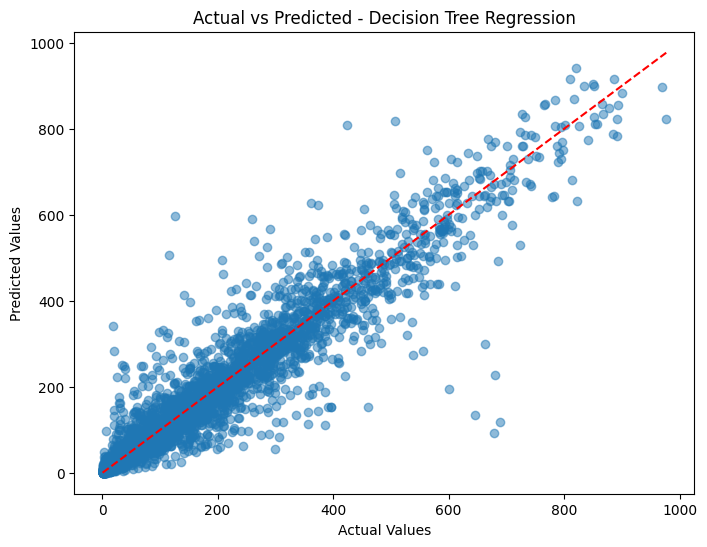

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred, alpha=0.5)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted - Decision Tree Regression")

plt.show()

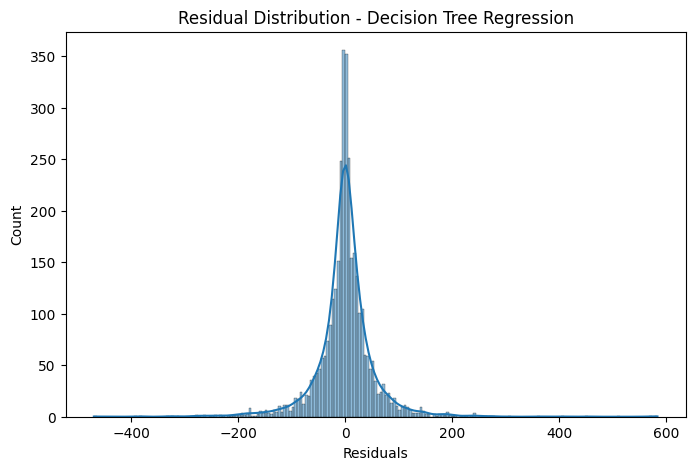

In [8]:
# Residual = Actual value - Predicted value

residuals = np.asarray(y_test).ravel() - y_test_pred

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.xlabel("Residuals")
plt.title("Residual Distribution - Decision Tree Regression")

plt.show()

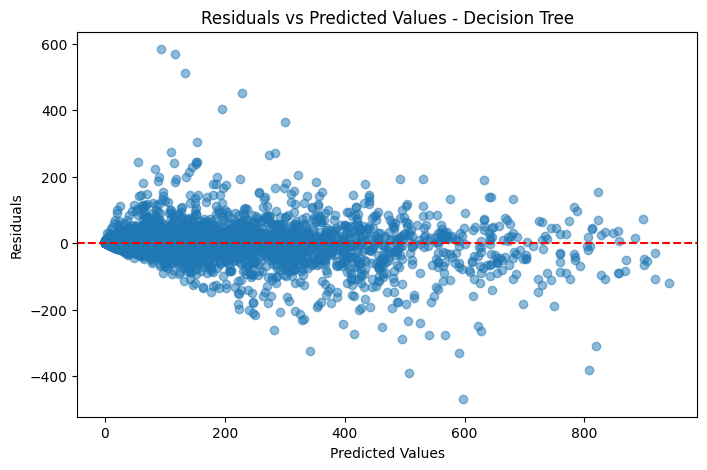

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test_pred, residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values - Decision Tree")

plt.show()

In [10]:
import pandas as pd
from bike_sharing_data import bike_sharing_dataset

X, y, _ = bike_sharing_dataset()

X.drop(columns=["dteday"], inplace=True)

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

,Feature,Importance
3,hr,0.611309
8,temp,0.114675
1,yr,0.080773
6,workingday,0.061860
10,hum,0.027524
0,season,0.023005
9,atemp,0.021200
7,weathersit,0.018177
2,mnth,0.016629
5,weekday,0.011802


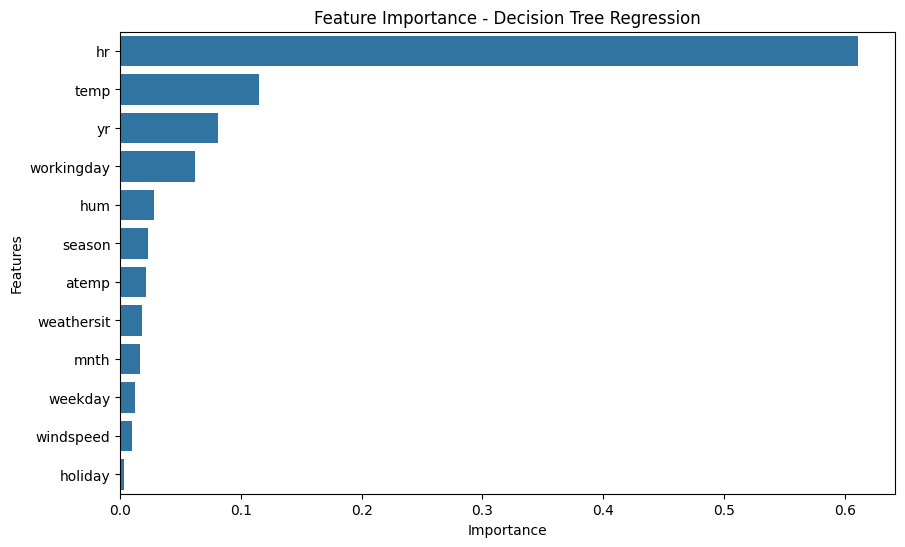

In [11]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title("Feature Importance - Decision Tree Regression")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.show()

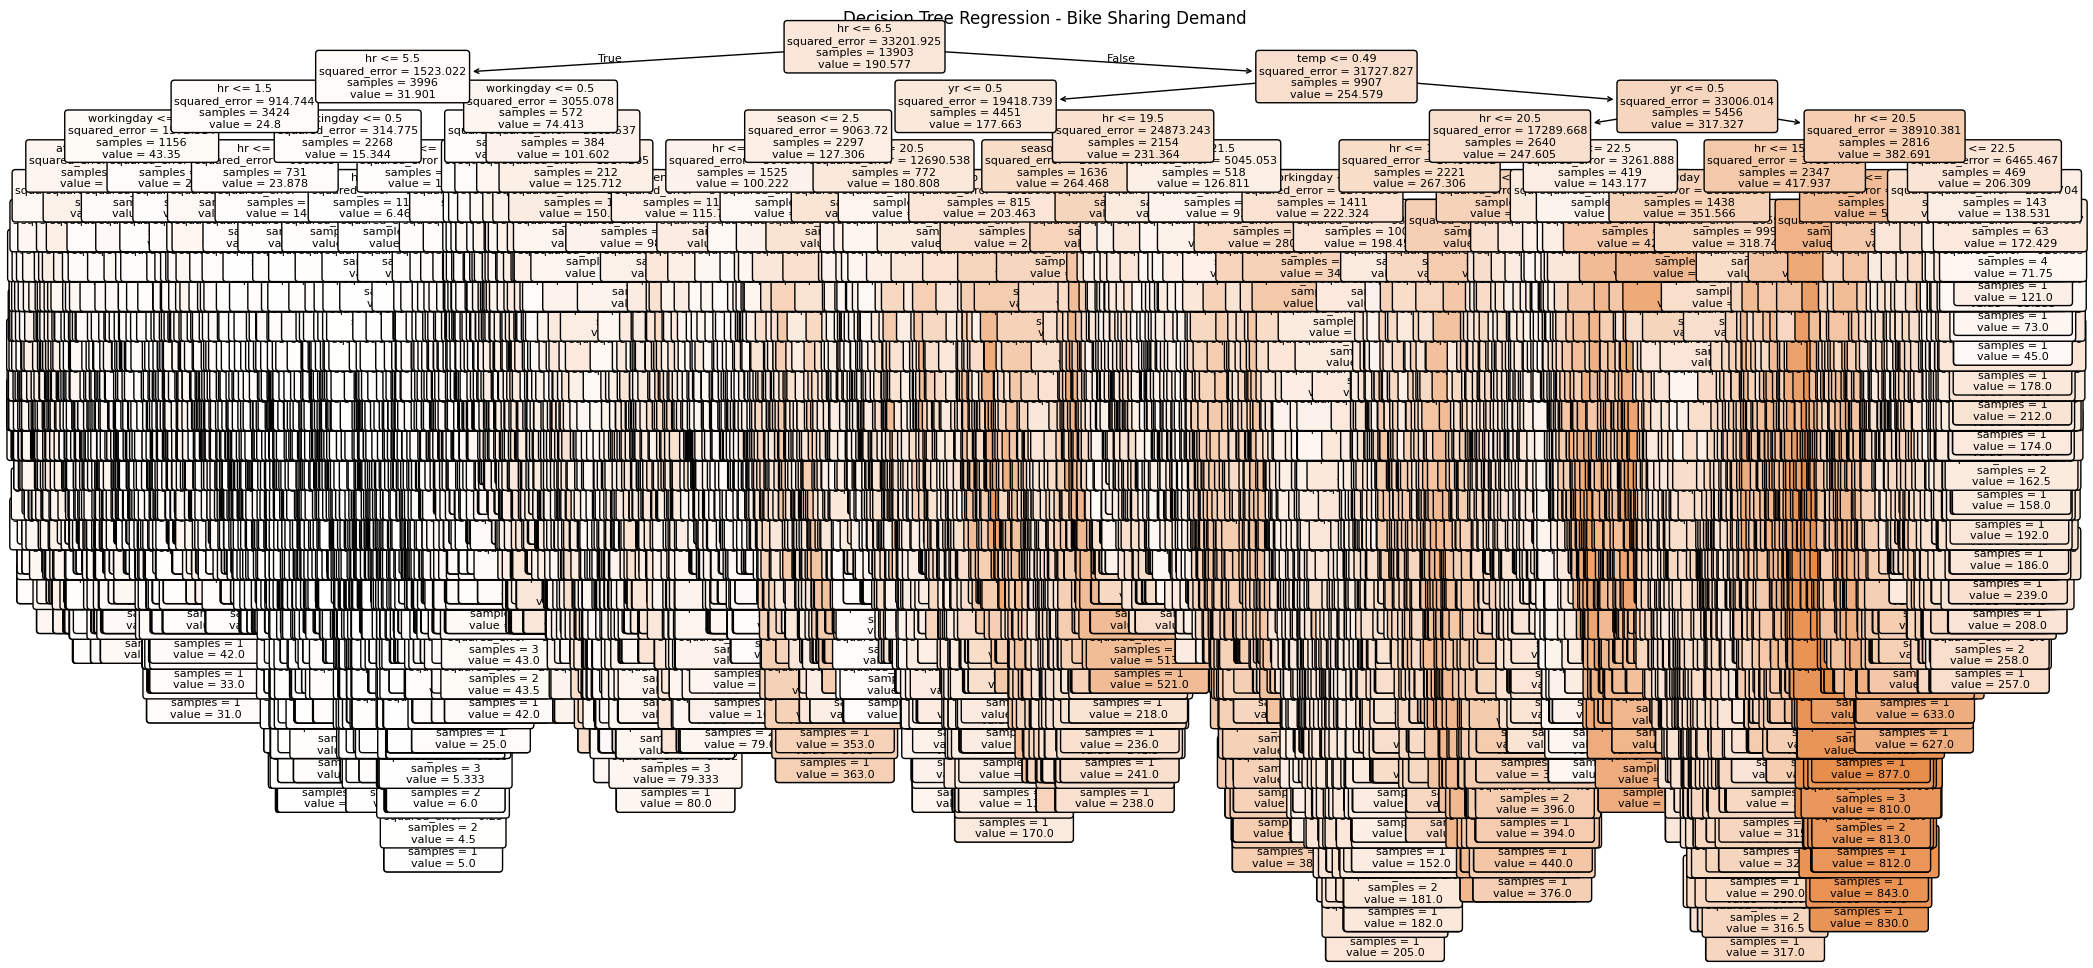

In [12]:
from sklearn.tree import plot_tree

plt.figure(figsize=(25, 12))

plot_tree(
    model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Regression - Bike Sharing Demand")

plt.show()

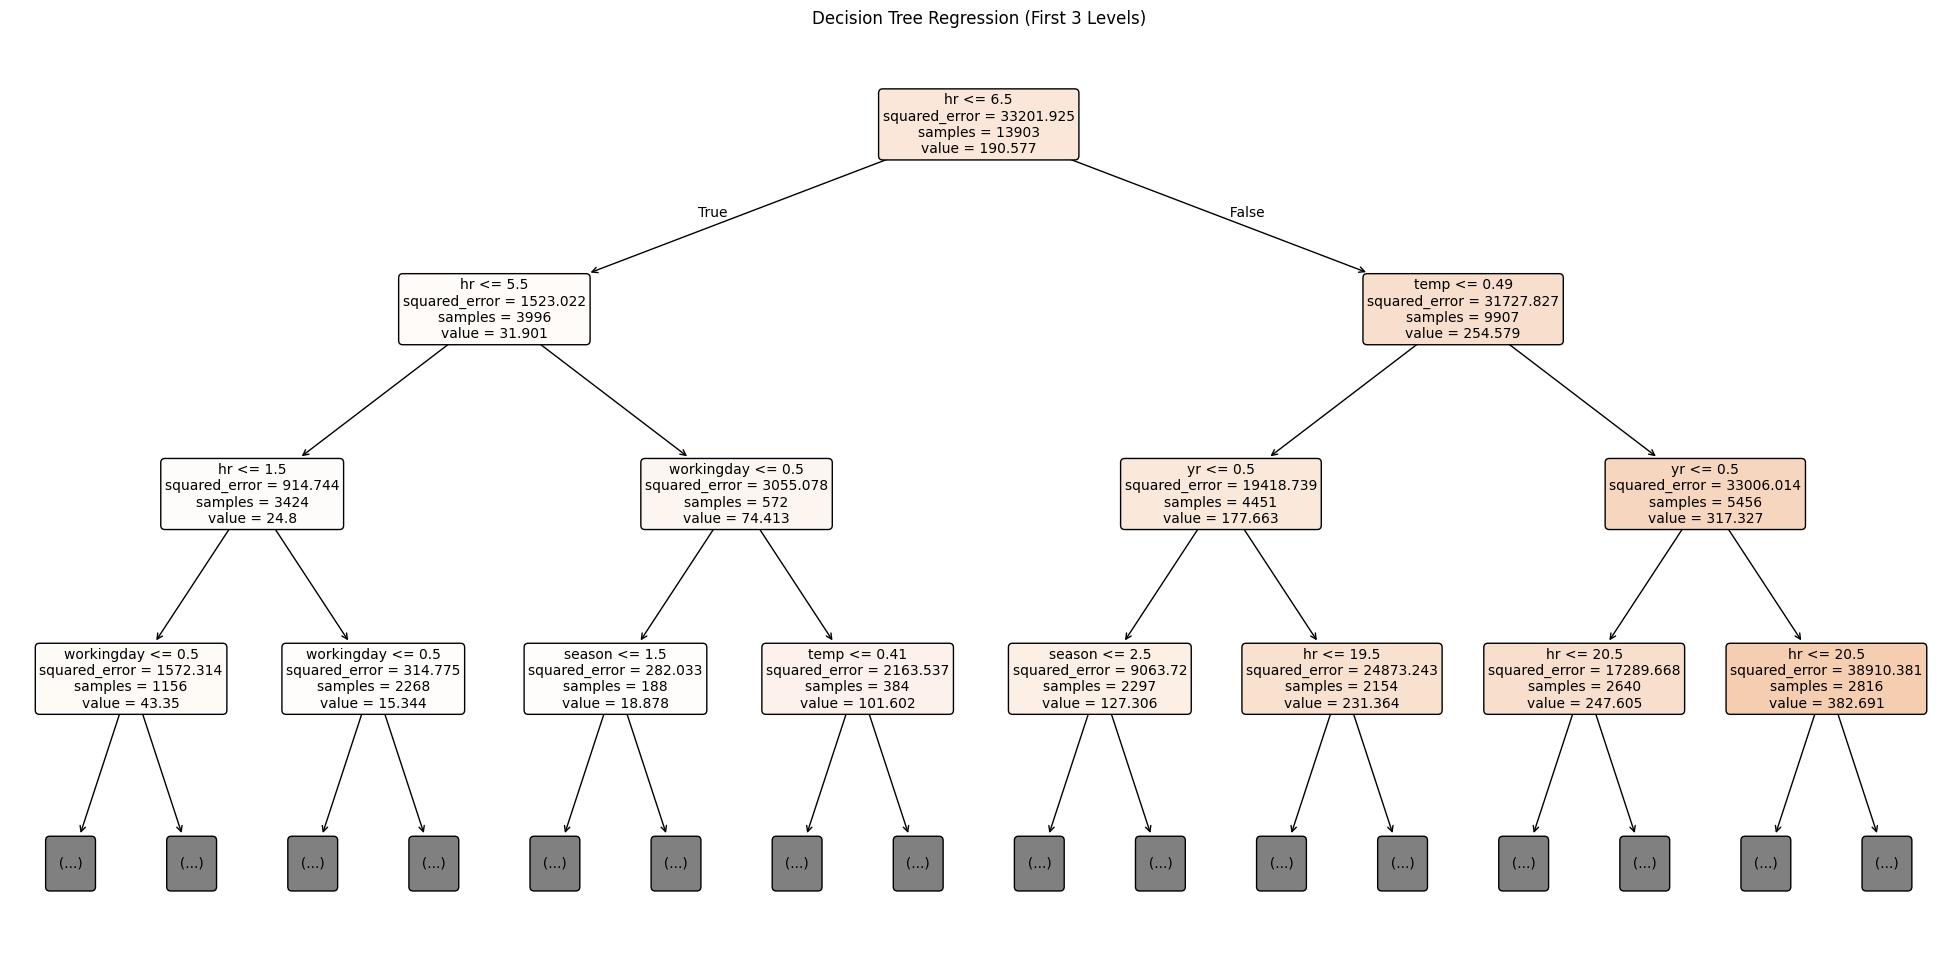

In [13]:
plt.figure(figsize=(25, 12))

plot_tree(
    model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=3
)

plt.title("Decision Tree Regression (First 3 Levels)")

plt.show()

In [ ]:
# to have more depth control on decision tree model config

model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)